# Personalized Online Course Recommender System
### Machine Learning Capstone: Christopher Guerrero

**Objective.** Recommend new online courses to learners, using IBM's course catalog and enrollment data. We compare two families of recommenders:

* **Content-based recommenders (unsupervised):** use what courses are about (genres and text) and what each learner has already taken.
  1. User profile and course genres
  2. Course similarity (bag-of-words features)
  3. Clustering of user profiles
* **Collaborative-filtering recommenders (supervised):** learn from the ratings of all learners.
  1. KNN (item-based)
  2. Non-negative matrix factorization (NMF)
  3. Neural network embeddings, plus regression and classification models built on those embeddings

**Outline:** 1. Data · 2. Exploratory data analysis · 3. Content-based recommenders · 4. Collaborative filtering · 5. Saved results

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")  # Keras 3 is backend-agnostic; PyTorch gives GPU access on this machine

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras import layers
from wordcloud import WordCloud, STOPWORDS
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, mean_squared_error, recall_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from surprise import NMF, Dataset, KNNBasic, Reader
from surprise import accuracy as surprise_accuracy
from surprise.model_selection import GridSearchCV

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML321EN-SkillsNetwork/labs/datasets/"
DATA_DIR, FIG_DIR, OUT_DIR = Path("data"), Path("figures"), Path("results")
for folder in (DATA_DIR, FIG_DIR, OUT_DIR):
    folder.mkdir(exist_ok=True)

PALETTE = ["#0F4C5C", "#E36414", "#5F0F40", "#9A031E", "#3A7D44", "#FB8B24"]
sns.set_theme(style="whitegrid")
metrics = {}


def load(name):
    # Read a capstone dataset, downloading it from IBM's course storage on first use.
    path = DATA_DIR / name
    if not path.exists():
        pd.read_csv(DATA_URL + name).to_csv(path, index=False)
    return pd.read_csv(path)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


print(f"Keras {keras.__version__} | backend: {keras.backend.backend()}")

Keras 3.15.1 | backend: torch


## 1. Data
Six files from IBM's ML capstone (IBM-ML321EN):

| File | Contents |
|---|---|
| `ratings.csv` | One row per enrollment: user, course and rating (2 = audited, 3 = completed) |
| `course_genre.csv` | 307 courses with 14 binary genre flags |
| `course_processed.csv` | Course titles and descriptions |
| `courses_bows.csv` | Bag-of-words token counts per course |
| `user_profile.csv` | Genre-interest profile per user (rating-weighted sum of the genres of the user's courses) |
| `rs_content_test.csv` | Enrollments of 1,000 test users for the content-based evaluation |

In [2]:
ratings = load("ratings.csv")
courses = load("course_genre.csv")
course_text = load("course_processed.csv")
bows = load("courses_bows.csv")
profiles = load("user_profile.csv")
test_enrollments = load("rs_content_test.csv")

GENRES = list(courses.columns[2:])
titles = courses.set_index("COURSE_ID")["TITLE"]
course_ids = courses["COURSE_ID"].tolist()

summary = {
    "enrollments": len(ratings),
    "users": int(ratings["user"].nunique()),
    "rated_courses": int(ratings["item"].nunique()),
    "catalog_courses": len(courses),
    "genres": len(GENRES),
    "rating_counts": {str(k): int(v) for k, v in ratings["rating"].value_counts().sort_index().items()},
    "test_users": int(test_enrollments["user"].nunique()),
    "test_enrollments": len(test_enrollments),
}
metrics["data"] = summary
for key, value in summary.items():
    print(f"{key:>18}: {value}")
print("Duplicate user-course pairs:", int(ratings.duplicated(["user", "item"]).sum()))

       enrollments: 233306
             users: 33901
     rated_courses: 126
   catalog_courses: 307
            genres: 14
     rating_counts: {'2.0': 10976, '3.0': 222330}
        test_users: 1000
  test_enrollments: 9402
Duplicate user-course pairs: 0


## 2. Exploratory data analysis

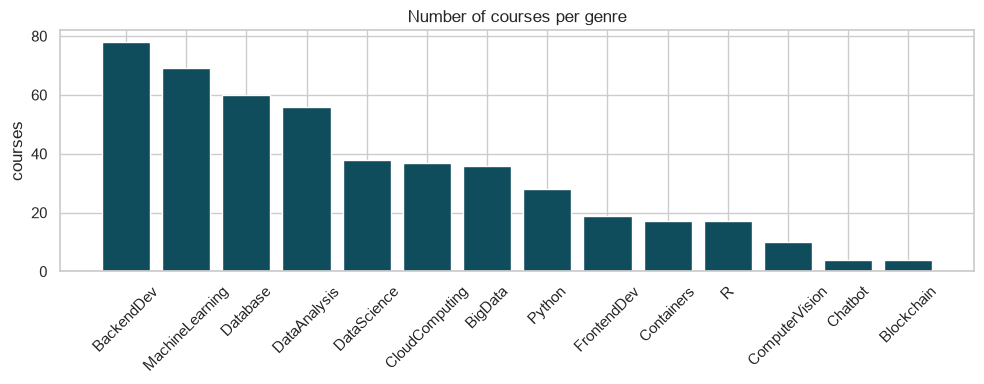

,BackendDev,MachineLearning,Database,DataAnalysis,DataScience,CloudComputing,BigData,Python,FrontendDev,Containers,R,ComputerVision,Chatbot,Blockchain
courses,78,69,60,56,38,37,36,28,19,17,17,10,4,4


In [3]:
genre_counts = courses[GENRES].sum().sort_values(ascending=False)
metrics["genre_counts"] = {g: int(n) for g, n in genre_counts.items()}

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(genre_counts.index, genre_counts.values, color=PALETTE[0])
ax.set_title("Number of courses per genre")
ax.set_ylabel("courses")
ax.tick_params(axis="x", rotation=45)
save(fig, "genre_counts.png")
genre_counts.to_frame("courses").T

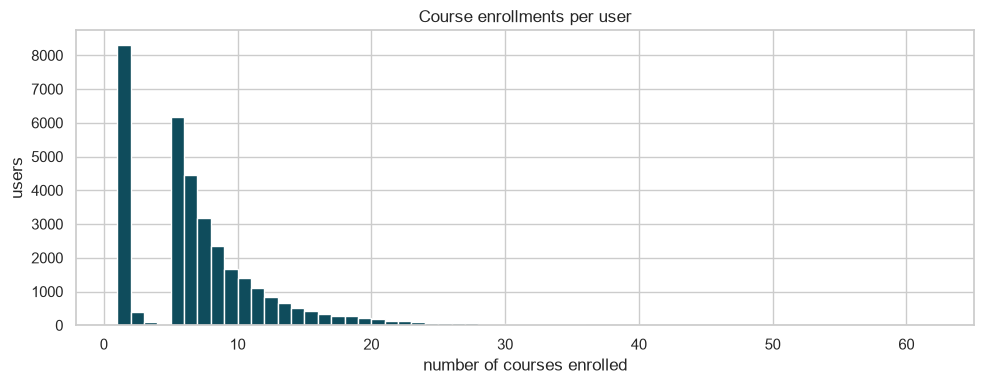

count    33901.00
mean         6.88
std          5.82
min          1.00
25%          2.00
50%          6.00
75%          9.00
max         61.00
dtype: float64

In [4]:
enrollments_per_user = ratings.groupby("user").size()
metrics["enrollment_distribution"] = {
    "counts": {int(k): int(v) for k, v in enrollments_per_user.value_counts().sort_index().items()},
    "mean": float(enrollments_per_user.mean()),
    "median": float(enrollments_per_user.median()),
    "max": int(enrollments_per_user.max()),
    "pct_users_5_or_fewer": float(100 * (enrollments_per_user <= 5).mean()),
}

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(enrollments_per_user, bins=range(1, enrollments_per_user.max() + 2), color=PALETTE[0])
ax.set_title("Course enrollments per user")
ax.set_xlabel("number of courses enrolled")
ax.set_ylabel("users")
save(fig, "enrollment_distribution.png")
enrollments_per_user.describe().round(2)

In [5]:
course_enrollments = ratings.groupby("item").size().sort_values(ascending=False)
top20 = course_enrollments.head(20).rename("enrollments").to_frame()
top20.insert(0, "title", titles.reindex(top20.index).values)
top20_share = 100 * top20["enrollments"].sum() / len(ratings)
metrics["top20_courses"] = [{"course": c, "title": row.title, "enrollments": int(row.enrollments)} for c, row in top20.iterrows()]
metrics["top20_share_pct"] = float(top20_share)
print(f"The 20 most popular courses (of {len(course_enrollments)}) account for {top20_share:.1f}% of all enrollments")
top20

The 20 most popular courses (of 126) account for 63.3% of all enrollments


,title,enrollments
item,,
PY0101EN,python for data science,14936
DS0101EN,introduction to data science,14477
BD0101EN,big data 101,13291
BD0111EN,hadoop 101,10599
DA0101EN,data analysis with python,8303
DS0103EN,data science methodology,7719
ML0101ENv3,machine learning with python,7644
BD0211EN,spark fundamentals i,7551
DS0105EN,data science hands on with open source tools,7199


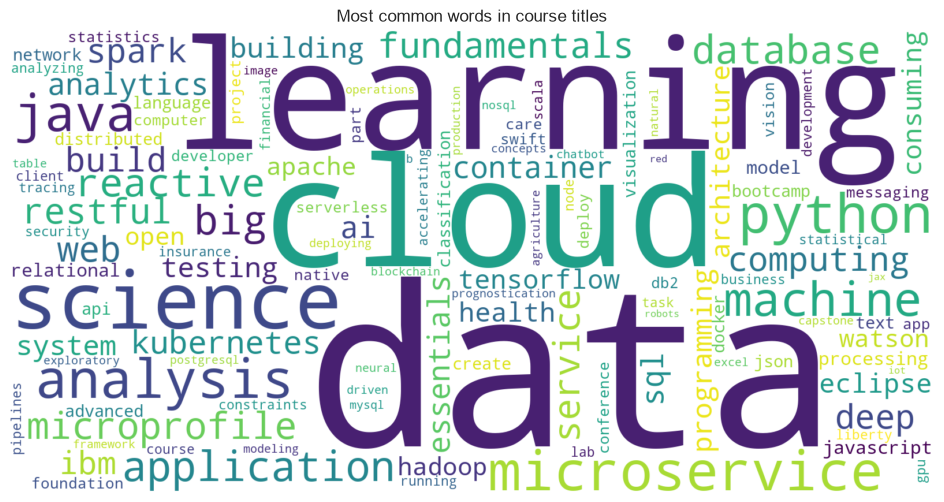

data            89
cloud           32
learning        32
science         30
microservice    28
python          27
analysis        27
java            24
machine         21
application     16
big             15
microprofile    14
dtype: int64

In [6]:
stopwords = set(STOPWORDS) | {"getting", "started", "using", "enabling", "template", "university", "end", "introduction", "basic", "basics"}
title_text = " ".join(courses["TITLE"].astype(str))
cloud = WordCloud(width=1600, height=800, background_color="white", stopwords=stopwords, max_words=120,
                  colormap="viridis", random_state=SEED, collocations=False).generate(title_text)
cloud.to_file(FIG_DIR / "wordcloud_titles.png")

word_freq = pd.Series(cloud.process_text(title_text)).sort_values(ascending=False)
metrics["top_title_words"] = {w: int(n) for w, n in word_freq.head(12).items()}

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Most common words in course titles")
plt.show()
word_freq.head(12)

## 3. Content-based recommenders (unsupervised)

All three methods score every course a test user hasn't taken, and recommend the courses whose score passes a threshold. To make the methods comparable, each threshold is tuned so that test users receive **about 10 new courses on average**. We report:
* the average number of new courses recommended per user
* the 10 courses recommended most often across all test users
* the share of users who get no recommendation, and how many distinct courses are ever recommended (catalog coverage)

In [7]:
enrolled = test_enrollments.groupby("user")["item"].apply(set)
TARGET_RECS = 10
content_results = {}


def mask_enrolled(score_df):
    # Courses a user already took can't be recommended to them.
    masked = score_df.copy()
    for user, items in enrolled.items():
        masked.loc[user, masked.columns.intersection(list(items))] = np.nan
    return masked


def sweep(score_df, grid):
    return pd.DataFrame({"threshold": grid,
                         "avg_recs_per_user": [float((score_df >= t).sum(axis=1).mean()) for t in grid]})


def choose_threshold(sweep_table):
    best = (sweep_table["avg_recs_per_user"] - TARGET_RECS).abs().idxmin()
    return float(sweep_table.loc[best, "threshold"])


def summarize(score_df, threshold, sweep_table):
    recommended = score_df >= threshold
    per_user = recommended.sum(axis=1)
    times = recommended.sum(axis=0).sort_values(ascending=False)
    return {
        "threshold": threshold,
        "avg_recs_per_user": float(per_user.mean()),
        "median_recs_per_user": float(per_user.median()),
        "pct_users_with_no_recs": float(100 * (per_user == 0).mean()),
        "distinct_courses_recommended": int((times > 0).sum()),
        "top10": [{"course": c, "title": titles[c], "times_recommended": int(n)} for c, n in times.head(10).items()],
        "sweep": sweep_table.to_dict(orient="records"),
    }


def show(result):
    print(f"threshold {result['threshold']} -> {result['avg_recs_per_user']:.2f} new courses per user on average "
          f"(median {result['median_recs_per_user']:.0f}; {result['pct_users_with_no_recs']:.1f}% of users get none; "
          f"{result['distinct_courses_recommended']} distinct courses recommended)")
    return pd.DataFrame(result["top10"])

### 3.1 User profile and course genres
A user's profile is a 14-value vector of genre interests (the rating-weighted sum of the genres of their courses). A course's score for that user is the **dot product** of the profile and the course's genre vector.

In [8]:
genre_matrix = courses.set_index("COURSE_ID")[GENRES]
test_profiles = profiles.set_index("user").loc[enrolled.index, GENRES]
profile_scores = mask_enrolled(pd.DataFrame(test_profiles.values @ genre_matrix.values.T,
                                            index=test_profiles.index, columns=genre_matrix.index))
profile_sweep = sweep(profile_scores, [10, 15, 20, 25, 30, 35, 40])
content_results["User profile"] = summarize(profile_scores, choose_threshold(profile_sweep), profile_sweep)
display(profile_sweep)
show(content_results["User profile"])

,threshold,avg_recs_per_user
0,10,53.411
1,15,34.787
2,20,16.710
3,25,8.229
4,30,5.876
5,35,3.080
6,40,1.776


threshold 25.0 -> 8.23 new courses per user on average (median 0; 60.3% of users get none; 232 distinct courses recommended)


,course,title,times_recommended
0,excourse73,analyzing big data with sql,234
1,excourse72,foundations for big data analysis with sql,234
2,TMP0105EN,getting started with the data apache spark ma...,230
3,RP0105EN,analyzing big data in r using apache spark,218
4,SC0103EN,spark overview for scala analytics,208
5,excourse31,cloud computing applications part 2 big data...,190
6,BD0212EN,spark fundamentals ii,181
7,excourse70,big data capstone project,152
8,excourse42,big data analysis hive spark sql dataframes...,152
9,excourse10,database architecture scale and nosql with e...,152


### 3.2 Course similarity (bag of words)
Each course becomes a bag-of-words vector of its title and description tokens. **Cosine similarity** between those vectors measures how alike two courses are. A course's score for a user is its highest similarity to any course the user already took.

In [9]:
bow_matrix = bows.pivot_table(index="doc_id", columns="token", values="bow", fill_value=0)
course_similarity = pd.DataFrame(cosine_similarity(bow_matrix.values), index=bow_matrix.index, columns=bow_matrix.index)
print("BoW matrix:", bow_matrix.shape, "| similarity matrix:", course_similarity.shape)

similarity_scores = mask_enrolled(pd.DataFrame(
    {user: course_similarity.loc[list(items)].max(axis=0) for user, items in enrolled.items()}).T)
similarity_sweep = sweep(similarity_scores, [0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75])
content_results["Course similarity"] = summarize(similarity_scores, choose_threshold(similarity_sweep), similarity_sweep)

# Worked example for the slides: the most similar courses to the most popular course
example = course_enrollments.index[0]
neighbors = course_similarity[example].drop(example).nlargest(4)
metrics["similarity_example"] = {"course": example, "title": titles[example],
                                 "neighbors": [{"course": c, "title": titles[c], "similarity": float(s)} for c, s in neighbors.items()]}
print(f"Most similar to '{titles[example]}':", [(titles[c], round(s, 2)) for c, s in neighbors.items()])
display(similarity_sweep)
show(content_results["Course similarity"])

BoW matrix: (307, 2697) | similarity matrix: (307, 307)


Most similar to 'python for data science': [('introduction to data science in python', 0.65), ('introduction to data science in python', 0.65), ('data science bootcamp with python', 0.55), ('python and statistics for financial analysis', 0.49)]


,threshold,avg_recs_per_user
0,0.45,41.894
1,0.50,26.391
2,0.55,18.577
3,0.60,11.377
4,0.65,6.729
5,0.70,3.702
6,0.75,0.862


threshold 0.6 -> 11.38 new courses per user on average (median 10; 1.7% of users get none; 59 distinct courses recommended)


,course,title,times_recommended
0,excourse62,introduction to data science in python,579
1,excourse22,introduction to data science in python,579
2,DS0110EN,data science with open data,562
3,excourse63,a crash course in data science,555
4,excourse65,data science fundamentals for data analysts,555
5,excourse72,foundations for big data analysis with sql,551
6,excourse68,big data modeling and management systems,550
7,excourse67,introduction to big data,539
8,excourse74,fundamentals of big data,539
9,BD0145EN,sql access for hadoop,506


### 3.3 Clustering of user profiles
User profiles are standardized, reduced with **PCA** (keeping 90% of the variance), and grouped with **K-means**, with the number of clusters chosen by the elbow method. A course's score for a user is the share of users in the same cluster who took it, so users are recommended what is popular among learners like them.

PCA keeps 9 of 14 components (92.7% of variance); elbow at k = 9


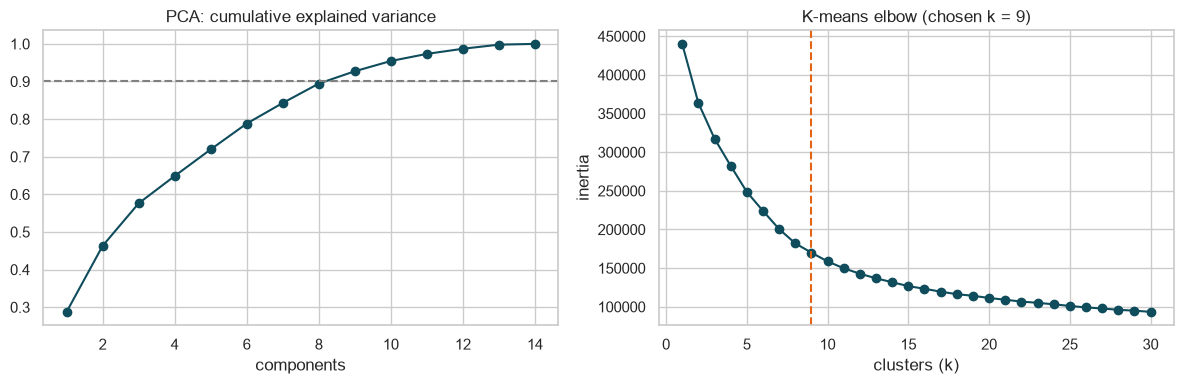

In [10]:
scaler = StandardScaler().fit(profiles[GENRES])
X_profiles = scaler.transform(profiles[GENRES])
cum_variance = np.cumsum(PCA(random_state=SEED).fit(X_profiles).explained_variance_ratio_)
n_components = int(np.searchsorted(cum_variance, 0.90) + 1)
pca = PCA(n_components=n_components, random_state=SEED).fit(X_profiles)
Z = pca.transform(X_profiles)

k_values = np.arange(1, 31)
inertias = np.array([KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in k_values])
# Elbow = the point farthest below the straight line joining the first and last points of the normalized curve
k_norm = (k_values - k_values.min()) / (k_values.max() - k_values.min())
i_norm = (inertias - inertias.min()) / (inertias.max() - inertias.min())
best_k = int(k_values[np.argmax(np.abs(k_norm + i_norm - 1) / np.sqrt(2))])
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(Z)
print(f"PCA keeps {n_components} of {len(GENRES)} components ({cum_variance[n_components - 1]:.1%} of variance); elbow at k = {best_k}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(1, len(cum_variance) + 1), cum_variance, marker="o", color=PALETTE[0])
ax1.axhline(0.9, ls="--", color="gray")
ax1.set_title("PCA: cumulative explained variance")
ax1.set_xlabel("components")
ax2.plot(k_values, inertias, marker="o", color=PALETTE[0])
ax2.axvline(best_k, ls="--", color=PALETTE[1])
ax2.set_title(f"K-means elbow (chosen k = {best_k})")
ax2.set_xlabel("clusters (k)")
ax2.set_ylabel("inertia")
save(fig, "clustering_elbow.png")

In [11]:
user_cluster = pd.Series(kmeans.labels_, index=profiles["user"], name="cluster")
cluster_sizes = user_cluster.value_counts().sort_index()
cluster_popularity = (ratings.assign(cluster=ratings["user"].map(user_cluster))
                      .groupby(["cluster", "item"]).size().unstack(fill_value=0)
                      .reindex(columns=course_ids, fill_value=0).div(cluster_sizes, axis=0))

cluster_scores = mask_enrolled(cluster_popularity.loc[user_cluster.loc[enrolled.index]].set_axis(enrolled.index))
cluster_sweep = sweep(cluster_scores, [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4])
content_results["Clustering"] = summarize(cluster_scores, choose_threshold(cluster_sweep), cluster_sweep)

# Describe each cluster by the genres its members are most above-average in (mean standardized interest).
# A cluster below average in every genre is a group of light users rather than a topic group.
member_z = pd.DataFrame(X_profiles, columns=GENRES).groupby(kmeans.labels_).mean()
cluster_activity = enrollments_per_user.groupby(user_cluster).mean()


def describe_cluster(c):
    above = member_z.loc[c][member_z.loc[c] > 0].nlargest(2)
    return above.index.tolist() if len(above) else ["Light users (below average in every genre)"]


cluster_info = [{"cluster": int(c), "users": int(cluster_sizes[c]), "top_genres": describe_cluster(c),
                 "avg_courses_per_user": float(cluster_activity[c])}
                for c in cluster_sizes.sort_values(ascending=False).index]
metrics["clustering"] = {"pca_components": n_components, "pca_variance": float(cum_variance[n_components - 1]),
                         "cumulative_variance": cum_variance.tolist(), "k_values": k_values.tolist(),
                         "inertias": inertias.tolist(), "best_k": best_k, "clusters": cluster_info}
display(pd.DataFrame(cluster_info))
display(cluster_sweep)
show(content_results["Clustering"])

,cluster,users,top_genres,avg_courses_per_user
0,1,11375,[Light users (below average in every genre)],2.049495
1,8,7284,"[Python, DataScience]",7.353652
2,6,4587,"[BigData, Database]",8.126880
3,2,3481,"[Containers, CloudComputing]",8.728814
4,5,3128,"[Chatbot, Python]",8.583120
5,3,2552,"[R, DataScience]",11.717868
6,0,827,"[DataAnalysis, Database]",29.146312
7,7,647,"[FrontendDev, BackendDev]",11.731066
8,4,20,"[ComputerVision, BackendDev]",16.000000


,threshold,avg_recs_per_user
0,0.10,12.700
1,0.15,7.881
2,0.20,6.406
3,0.25,4.665
4,0.30,4.214
5,0.35,3.065
6,0.40,2.182


threshold 0.15 -> 7.88 new courses per user on average (median 8; 8.1% of users get none; 68 distinct courses recommended)


,course,title,times_recommended
0,BD0101EN,big data 101,461
1,DS0101EN,introduction to data science,449
2,BD0111EN,hadoop 101,447
3,DS0103EN,data science methodology,425
4,BC0101EN,blockchain essentials,424
5,ML0101ENv3,machine learning with python,373
6,DB0101EN,sql and relational databases 101,368
7,ST0101EN,statistics 101,338
8,BD0211EN,spark fundamentals i,329
9,ML0115EN,deep learning 101,321


### 3.4 Do the recommendations match what learners actually take?
The metrics above describe *how many* courses are recommended, not whether they are *good*. As an extra check, for each test user with at least two enrollments we **hide one enrolled course**, rebuild the user's inputs from the remaining courses, and test whether the hidden course appears in that method's **top 10**. All methods rank the same candidates (the 126 courses that have enrollment data), and a global most-popular ranking serves as the baseline.

In [12]:
rng = np.random.default_rng(SEED)
user_courses = ratings.groupby("user")["item"].apply(list)
user_ratings = ratings.set_index(["user", "item"])["rating"]
candidates = course_enrollments.index  # courses with enrollment data
global_popularity = course_enrollments.astype(float)

hits = {"User profile": [], "Course similarity": [], "Clustering": [], "Most popular (baseline)": []}
for user in enrolled.index:
    taken = user_courses[user]
    if len(taken) < 2:
        continue
    hidden = rng.choice(taken)
    known = [c for c in taken if c != hidden]

    profile = sum(user_ratings[(user, c)] * genre_matrix.loc[c].values for c in known)
    cluster = kmeans.predict(pca.transform(scaler.transform(pd.DataFrame([profile], columns=GENRES))))[0]
    method_scores = {
        "User profile": pd.Series(genre_matrix.loc[candidates].values @ profile, index=candidates),
        "Course similarity": course_similarity.loc[known, candidates].max(axis=0),
        "Clustering": cluster_popularity.loc[cluster, candidates],
        "Most popular (baseline)": global_popularity,
    }
    for name, scores in method_scores.items():
        top10 = scores.drop(labels=known, errors="ignore").nlargest(10).index
        hits[name].append(hidden in top10)

hit_rates = {name: float(100 * np.mean(h)) for name, h in hits.items()}
metrics["holdout_hit_rate_at_10"] = {"users_evaluated": len(hits["User profile"]), "hit_rate_pct": hit_rates,
                                     "random_pct": float(100 * 10 / (len(candidates) - 1))}
pd.Series(hit_rates, name="hit rate @10 (%)").round(1)

User profile               29.9
Course similarity          27.1
Clustering                 66.3
Most popular (baseline)    57.4
Name: hit rate @10 (%), dtype: float64

In [13]:
metrics["content_based"] = content_results
pd.DataFrame({name: {k: r[k] for k in ["threshold", "avg_recs_per_user", "pct_users_with_no_recs", "distinct_courses_recommended"]}
              for name, r in content_results.items()}).T.round(2)

,threshold,avg_recs_per_user,pct_users_with_no_recs,distinct_courses_recommended
User profile,25.00,8.23,60.3,232.0
Course similarity,0.60,11.38,1.7,59.0
Clustering,0.15,7.88,8.1,68.0


## 4. Collaborative filtering (supervised)
These models predict the rating a user would give a course from the ratings of all users. We hold out 20% of the ratings as a test set and compare models by **RMSE** on that set. Ratings are 2 or 3, and about 95% are 3, so the baseline that always predicts the average rating is a demanding benchmark.

In [14]:
train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=SEED)
global_mean = train_df["rating"].mean()


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


cf_results = {"Baseline (global mean)": {"rmse": rmse(test_df["rating"], np.full(len(test_df), global_mean))}}
reader = Reader(rating_scale=(2, 3))
train_data = Dataset.load_from_df(train_df[["user", "item", "rating"]], reader)
trainset = train_data.build_full_trainset()
testset = list(test_df[["user", "item", "rating"]].itertuples(index=False, name=None))
print(f"train {len(train_df):,} | test {len(test_df):,} | baseline RMSE {cf_results['Baseline (global mean)']['rmse']:.4f}")

train 186,644 | test 46,662 | baseline RMSE 0.2109


### 4.1 KNN (item-based)
Predicts a user's rating for a course from their ratings of the *k* most similar courses. Item-based similarity is used because a user-based model would need a 33,901 x 33,901 similarity matrix. *k* and the similarity measure are tuned with 3-fold cross-validation on the training set.

In [15]:
start = time.perf_counter()
knn_search = GridSearchCV(KNNBasic, {"k": [10, 20, 40], "sim_options": {"name": ["cosine", "msd"], "user_based": [False]},
                                     "verbose": [False]}, measures=["rmse"], cv=3, n_jobs=1)
knn_search.fit(train_data)
knn_params = knn_search.best_params["rmse"]
knn = KNNBasic(**knn_params).fit(trainset)
cf_results["KNN (item-based)"] = {"rmse": float(surprise_accuracy.rmse(knn.test(testset), verbose=False)),
                                  "params": {"k": knn_params["k"], "similarity": knn_params["sim_options"]["name"]},
                                  "seconds": round(time.perf_counter() - start, 1)}
cf_results["KNN (item-based)"]

{'rmse': 0.191017553874792,
 'params': {'k': 10, 'similarity': 'msd'},
 'seconds': 8.6}

### 4.2 Non-negative matrix factorization (NMF)
Factorizes the sparse user x course rating matrix into non-negative user and course latent-factor matrices, whose product estimates the missing ratings. The number of latent factors is tuned with 3-fold cross-validation.

In [16]:
start = time.perf_counter()
nmf_search = GridSearchCV(NMF, {"n_factors": [8, 16, 32], "n_epochs": [50], "random_state": [SEED]}, measures=["rmse"], cv=3)
nmf_search.fit(train_data)
nmf_params = nmf_search.best_params["rmse"]
nmf = NMF(**nmf_params).fit(trainset)
cf_results["NMF"] = {"rmse": float(surprise_accuracy.rmse(nmf.test(testset), verbose=False)),
                     "params": {"n_factors": nmf_params["n_factors"], "n_epochs": nmf_params["n_epochs"]},
                     "seconds": round(time.perf_counter() - start, 1)}
cf_results["NMF"]

{'rmse': 0.1874839821995905,
 'params': {'n_factors': 32, 'n_epochs': 50},
 'seconds': 35.7}

### 4.3 Neural network embeddings (RecommenderNet)
Each user and each course gets a learned 16-dimensional **embedding vector** plus a bias. The predicted rating is the sigmoid of their dot product plus the biases, trained on ratings rescaled to [0, 1].

In [17]:
user_ids, item_ids = ratings["user"].unique(), ratings["item"].unique()
user_index = {u: i for i, u in enumerate(user_ids)}
item_index = {c: i for i, c in enumerate(item_ids)}


def encode(df):
    x = np.stack([df["user"].map(user_index).values, df["item"].map(item_index).values], axis=1).astype("int64")
    return x, (df["rating"].values - 2.0).astype("float32")  # 2 -> 0, 3 -> 1


EMBEDDING_DIM = 16


class RecommenderNet(keras.Model):
    def __init__(self, n_users, n_items, dim, **kwargs):
        super().__init__(**kwargs)
        reg = keras.regularizers.l2(1e-6)
        self.user_embedding = layers.Embedding(n_users, dim, embeddings_initializer="he_normal", embeddings_regularizer=reg)
        self.item_embedding = layers.Embedding(n_items, dim, embeddings_initializer="he_normal", embeddings_regularizer=reg)
        self.user_bias = layers.Embedding(n_users, 1)
        self.item_bias = layers.Embedding(n_items, 1)

    def call(self, inputs):
        users, items = inputs[:, 0], inputs[:, 1]
        dot = keras.ops.sum(self.user_embedding(users) * self.item_embedding(items), axis=1, keepdims=True)
        return keras.ops.sigmoid(dot + self.user_bias(users) + self.item_bias(items))


X_train, y_train = encode(train_df)
X_test, y_test = encode(test_df)
recommender = RecommenderNet(len(user_ids), len(item_ids), EMBEDDING_DIM)
recommender.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
start = time.perf_counter()
history = recommender.fit(X_train, y_train, validation_split=0.1, epochs=30, batch_size=512, verbose=2,
                          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
nn_pred = recommender.predict(X_test, batch_size=4096, verbose=0).ravel()
cf_results["Neural network embeddings"] = {"rmse": rmse(y_test, nn_pred), "params": {"embedding_dim": EMBEDDING_DIM, "epochs": len(history.history["loss"])},
                                           "seconds": round(time.perf_counter() - start, 1)}
metrics["nn_history"] = {k: [float(v) for v in vals] for k, vals in history.history.items()}
cf_results["Neural network embeddings"]

Epoch 1/30


329/329 - 2s - 6ms/step - loss: 0.2090 - rmse: 0.4570 - val_loss: 0.1595 - val_rmse: 0.3988


Epoch 2/30


329/329 - 1s - 4ms/step - loss: 0.0989 - rmse: 0.3121 - val_loss: 0.0586 - val_rmse: 0.2363


Epoch 3/30


...

Epoch 26/30


329/329 - 1s - 4ms/step - loss: 0.0064 - rmse: 0.0450 - val_loss: 0.0164 - val_rmse: 0.1096


Epoch 27/30


329/329 - 1s - 4ms/step - loss: 0.0062 - rmse: 0.0443 - val_loss: 0.0165 - val_rmse: 0.1110


{'rmse': 0.10616340842744866,
 'params': {'embedding_dim': 16, 'epochs': 27},
 'seconds': 35.7}

### 4.4 Regression on embedding features
The trained user and course embeddings are reused as features: for each rating, the user vector and the course vector are **added element-wise** into one 16-value interaction feature vector, and a ridge regression predicts the rating from it.

In [18]:
user_vectors = keras.ops.convert_to_numpy(recommender.user_embedding.embeddings)
item_vectors = keras.ops.convert_to_numpy(recommender.item_embedding.embeddings)


def embedding_features(df):
    return user_vectors[df["user"].map(user_index).values] + item_vectors[df["item"].map(item_index).values]


F_train, F_test = embedding_features(train_df), embedding_features(test_df)
ridge = RidgeCV(alphas=[0.1, 1.0, 10.0, 100.0]).fit(F_train, train_df["rating"])
cf_results["Regression on embeddings"] = {"rmse": rmse(test_df["rating"], ridge.predict(F_test).clip(2, 3)),
                                          "params": {"model": "ridge", "alpha": float(ridge.alpha_)}}
cf_results["Regression on embeddings"]

{'rmse': 0.17603236177445122, 'params': {'model': 'ridge', 'alpha': 0.1}}

### 4.5 Classification on embedding features
The same features feed classifiers that predict the rating *class* (2 = audited, 3 = completed). Because 95% of ratings are 3, accuracy alone is misleading, so we also report **balanced accuracy**, **macro F1** and **recall on the minority class**.

In [19]:
label_encoder = LabelEncoder().fit(ratings["rating"])
y_train_cls, y_test_cls = label_encoder.transform(train_df["rating"]), label_encoder.transform(test_df["rating"])
minority = int(label_encoder.transform([2.0])[0])


def classification_scores(y_pred):
    return {"accuracy": float(accuracy_score(y_test_cls, y_pred)), "balanced_accuracy": float(balanced_accuracy_score(y_test_cls, y_pred)),
            "macro_f1": float(f1_score(y_test_cls, y_pred, average="macro")),
            "minority_recall": float(recall_score(y_test_cls, y_pred, pos_label=minority))}


classifiers = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=SEED),
}
classification_results = {"Majority class (baseline)": classification_scores(np.full(len(y_test_cls), 1 - minority))}
for name, clf in classifiers.items():
    classification_results[name] = classification_scores(clf.fit(F_train, y_train_cls).predict(F_test))
metrics["classification"] = classification_results
pd.DataFrame(classification_results).T.round(3)

,accuracy,balanced_accuracy,macro_f1,minority_recall
Majority class (baseline),0.953,0.500,0.488,0.000
Logistic regression,0.825,0.807,0.598,0.787
Random forest,0.993,0.948,0.961,0.899


### 4.6 Comparing the collaborative-filtering models

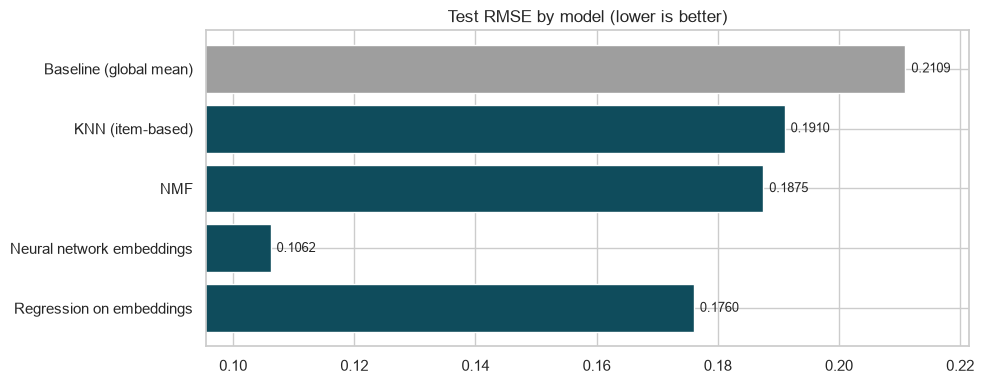

,test RMSE,improvement_vs_baseline_pct
Baseline (global mean),0.210945,0.00
KNN (item-based),0.191018,9.45
NMF,0.187484,11.12
Neural network embeddings,0.106163,49.67
Regression on embeddings,0.176032,16.55


In [20]:
metrics["collaborative_filtering"] = cf_results
comparison = pd.Series({name: r["rmse"] for name, r in cf_results.items()}, name="test RMSE")
baseline_rmse = comparison["Baseline (global mean)"]

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#9e9e9e" if name.startswith("Baseline") else PALETTE[0] for name in comparison.index]
ax.barh(comparison.index[::-1], comparison.values[::-1], color=colors[::-1])
for i, v in enumerate(comparison.values[::-1]):
    ax.text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(comparison.min() * 0.9, comparison.max() * 1.05)
ax.set_title("Test RMSE by model (lower is better)")
save(fig, "cf_rmse_comparison.png")
comparison.to_frame().assign(improvement_vs_baseline_pct=lambda d: (100 * (1 - d["test RMSE"] / baseline_rmse)).round(2))

## 5. Save results

In [21]:
metrics["environment"] = {"keras": keras.__version__, "backend": keras.backend.backend(), "seed": SEED}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
best_content = max(hit_rates, key=hit_rates.get)
best_cf = comparison.drop("Baseline (global mean)").idxmin()
print(f"Best content-based method on the hold-out test: {best_content} ({hit_rates[best_content]:.1f}% hit rate @10)")
print(f"Best collaborative-filtering model: {best_cf} (RMSE {comparison[best_cf]:.4f} vs baseline {baseline_rmse:.4f})")
print("Saved", OUT_DIR / "metrics.json")

Best content-based method on the hold-out test: Clustering (66.3% hit rate @10)
Best collaborative-filtering model: Neural network embeddings (RMSE 0.1062 vs baseline 0.2109)
Saved results\metrics.json


## 6. Conclusions
* **Enrollment data is concentrated.** The 20 most popular courses, mostly introductory data science, Python and big data, account for most enrollments, and most learners take only a handful of courses.
* **Among content-based methods, clustering wins the hold-out test.** Recommending what is popular among similar learners recovers hidden enrollments far more often than genre-profile or text-similarity scores, and beats the global most-popular baseline. Learners' next courses tend to be popular foundational courses, which pure content matching misses.
* **Fixed score thresholds treat users unevenly.** With an absolute threshold, heavy users get long lists while many light users get none; a rank-based top-N list would serve every learner.
* **Neural network embeddings are the strongest collaborative-filtering model.** They roughly halve the baseline RMSE, while item-based KNN and NMF give modest gains. The learned embeddings are also useful features: a random forest on them separates audited from completed enrollments with high balanced accuracy.
* **Next steps:** recommend top-N instead of thresholding, de-duplicate repeated catalog listings, build a hybrid of cluster popularity and embedding-based scores, and evaluate with ranking metrics (precision and recall @k) on recent enrollments.